NOTE: ORIGINAL .KINARM FILES + CSV FILES ARE TOO BIG TO UPLOAD TO GITHUB. A folder can be found in the **lab dropbox** under **projects -> sandbox -> dusty -> hayashi-data**

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import json
import numpy as np
import matplotlib.ticker as ticker

from matplotlib.lines import Line2D
from collections import defaultdict

Constants and helpful values:

In [2]:
# These are the same colors as in the hayashi paper
color_map = {
    -30: '#2e3092',
    -45: '#91278f',
    -15: '#00aeef',
     0:  '#444444',
     15: '#f7931d',
     30: '#ed1c24',
     45: '#ec008c'
}

# Within Kinarm, the proprioceptive perturbation levels weren't defined in degrees (was based on the offset in cm from the directly forward path). 
# # This is the mapping from that measurement (in the dataset) to degrees.
mapping = {
    -5.77400016784668: (-30*-1), # -30 in our experiment, but flipped to match Hayashi 
    -2.6800000667572: (-15*-1),
    0.0: 0,
    2.6800000667572: (15*-1),
    5.77400016784668: (30*-1)
}

# I'm using the same system in order to flip the visual perturbation levels, so that they match with Hayashi
# In our program, rotations are in the CCW direction, but in Hayashi they are CW
mapping_vis = {
    -45: 45,
    -30: 30,
    -15: 15,
     0: 0,
     15: -15,
     30: -30,
     45: -45
}

# Helpful lists later
vis_pert_levels = [-45,-30, -15, 0, 15, 30, 45]
prop_pert_levels=[-30, -15, 0, 15, 30]
prop_pert_unmapped_levels = [-5.77400016784668, -2.6800000667572, 0.0, 2.6800000667572, 5.77400016784668]   

# Constants
SEC_TO_MS = 1000


# In some of the analysis figures from the Hayashi paper, they include force profile data before RT/ force onset.
# This number is somewhat arbitrary, but chosen to match their graphs.
BUFFER = 150;


Helper functions:

In [3]:
def json_decode(val):
    if isinstance(val, str):
        try:
            return json.loads(val)
        except (json.JSONDecodeError, TypeError):
            return val
    return val

Notes about graphs!
- force: right is in positive direction


Extracting data from csv:

In [4]:
# file_path = "csv-files/dusty-hayashi.csv"
file_path = "csv-files/yoyo-hayashi.csv"
# file_path = "csv-files/Hayashi_P1_Eric.csv"

In [5]:
df_json = pd.read_csv(file_path)
df = df_json.map(json_decode)


In [6]:
df = df

In [7]:
# Extracting data

# Note about trial type: 1 = probe trial, 0= perturbation trial. 
# We want to match the force profiles from the probe trials to the perturbation levels from the perturbation trials, which is why the trial types are different
force_vals = df.loc[df['Trial Type'] == 1, 'Force X'].reset_index(drop=True)
vis_vals   = df.loc[df['Trial Type'] == 0, 'Visual Pert'].reset_index(drop=True)
prop_vals = df.loc[df['Trial Type'] == 0, 'Prop Pert'].reset_index(drop=True)

# Using RT time to find the force onset
onsets = (df.loc[df['Trial Type'] == 1, 'RTs'] * SEC_TO_MS).astype(int)
# Extracting the peak velocity time and converting to MS
peak_vels = (df.loc[df['Trial Type'] == 1, 'Time PV'] * SEC_TO_MS).astype(int)

In [8]:
# To create figure 3A/B:

aligned_forces = [
    force[onset-BUFFER:] 
    for force, onset in zip(force_vals, onsets)
]

# Data for figure 3a
forces_vis = list(zip(aligned_forces, vis_vals))
# Data for figure 3b
forces_prop = list(zip(aligned_forces, prop_vals))

**Figure 3A:** In the Hayashi paper, they don't include the 0° perturbation level, but I decided to include it here.

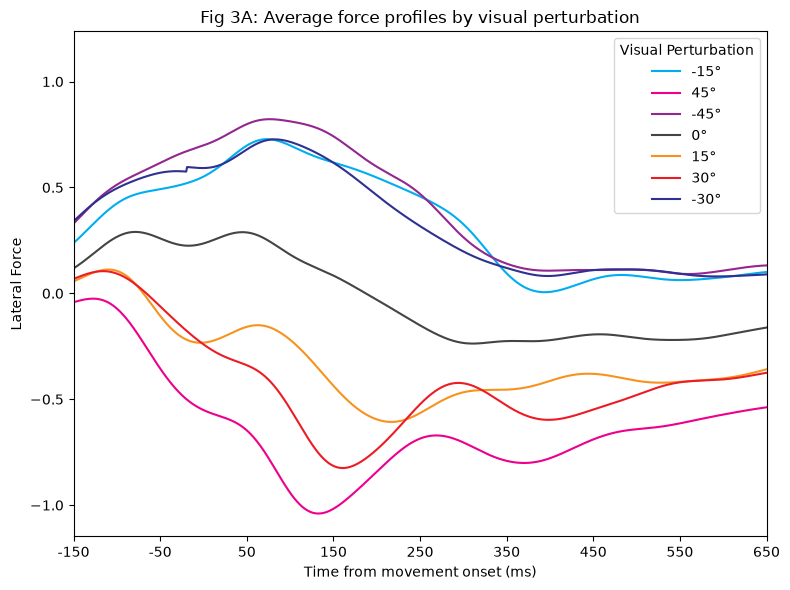

In [9]:
# Extracted the force profiles and visual perturbations from tuples to a dictionary for easier processing
force_vis_dict = defaultdict(list)

for force_array, vis_pert in forces_vis:
    force_vis_dict[vis_pert].append(force_array)
    
# Compute mean force profile per perturbation level
avg_forces = {}
for vis_pert, forces_list in force_vis_dict.items():
        # Not all of the force profiles are the same length,
        # so I padded the shorter ones with NaNs to be able to take the average without biasing towards the shorter profiles
    max_len = max(len(force_array) for force_array in forces_list)
    padded = []
    for force_array in forces_list:
        pad_width = max_len - len(force_array)
        if pad_width > 0:
            force_array_padded = np.pad(force_array, (0, pad_width), constant_values=np.nan)
        else:
            force_array_padded = force_array
        padded.append(force_array_padded)
    
    padded = np.array(padded)
    avg_forces[vis_pert] = np.nanmean(padded, axis=0)
    
# ---------------------------------------

plt.figure(figsize=(8, 6))

# Allows us to format the x-axis in terms of time relative to RT/ force onset
ax = plt.gca() 
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: int(x - BUFFER)))
ax.set_xlim(left=0, right=800)

# Plotting   
for visual_pert, avg_force_profile in avg_forces.items():
    # Flipping the sign of the graphed visual perturbation to match Hayashi 
    label = mapping_vis.get(visual_pert, str(visual_pert))
    color = color_map.get(label, None)
    plt.plot(avg_force_profile, label=f'{label}°', color=color)


plt.xlabel('Time from movement onset (ms)')
plt.ylabel('Lateral Force')
plt.legend(title="Visual Perturbation")
plt.title('Fig 3A: Average force profiles by visual perturbation')

plt.tight_layout()
plt.show()

**Figure 3B:** In the Hayashi paper, they don't include the 0° perturbation level, but I decided to include it here.

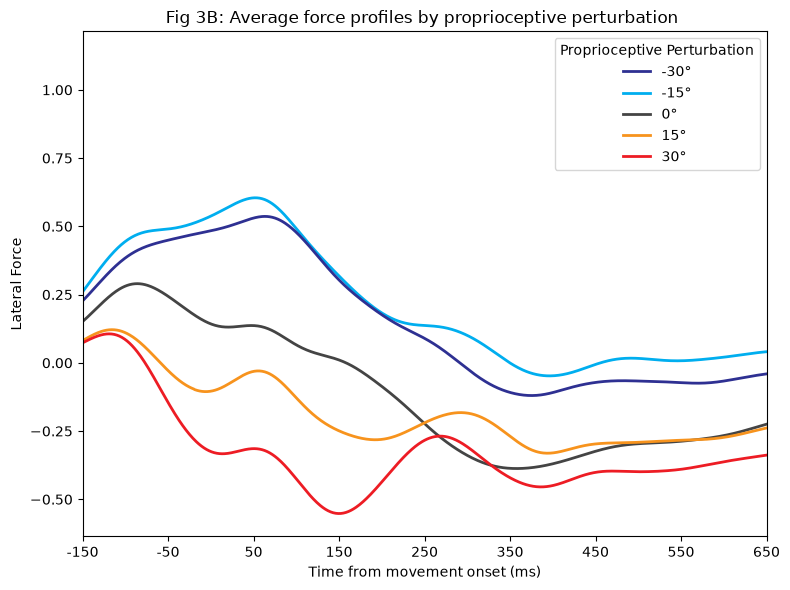

In [10]:
# Extracted the force profiles and proprioceptive perturbations from tuples to a dictionary for easier processing
force_prop_dict = defaultdict(list)

for force_array, prop in forces_prop:
    # Convert proprioceptive perts to degrees from Kinarm format
    mapped_prop = mapping.get(prop, prop)
    force_prop_dict[mapped_prop].append(force_array)

avg_forces = {}
for prop_pert, force_list in force_prop_dict.items():
    # Same padding process as above to handle different length force profiles
    max_len = max(len(force_array) for force_array in force_list)
    padded = []
    for force_array in force_list:
        pad_width = max_len - len(force_array)
        if pad_width > 0:
            force_array_padded = np.pad(force_array, (0, pad_width), constant_values=np.nan)
        else:
            force_array_padded = force_array
        padded.append(force_array_padded)

    padded = np.array(padded)
    avg_forces[prop_pert] = np.nanmean(padded, axis=0)
    
# ---------------------------------------

plt.figure(figsize=(8, 6))

# Allows us to format the x-axis in terms of time relative to RT/ force onset
ax = plt.gca()
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: int(x - BUFFER))
)
ax.set_xlim(left=0, right=800)

# Plotting
for prop, avg in avg_forces.items():
    color = color_map.get(prop, None)
    plt.plot(avg, color=color, linewidth=2)

legend_elements = [
    Line2D([0], [0],color=color_map.get(p, None), lw=2, label=f'{str(p)}°')
    for p in prop_pert_levels
]

plt.legend(handles=legend_elements, title="Proprioceptive Perturbation")
plt.xlabel('Time from movement onset (ms)')
plt.ylabel('Lateral Force')
plt.title('Fig 3B: Average force profiles by proprioceptive perturbation ')

plt.tight_layout()
plt.show()

In [11]:
# To create figure 3 C/D:

# Set up force profiles for integration
# This only goes from onset to peak velocity, rather than onset to end (which is what aligned_forces captures)
int_forces = [
    force[onset:peak_vel] 
    for force, onset, peak_vel in zip(force_vals, onsets, peak_vels)
]
# Based on the sampling rate of 1000 hz
dt = 0.001

# Integrate force profiles to get the after effects
# Quantified by hayashi as "integrated lateral force from the force onset to the time of peak velocity"
aftereffects = [np.trapezoid(segment, dx=dt) for segment in int_forces]

**Figure 3C:**

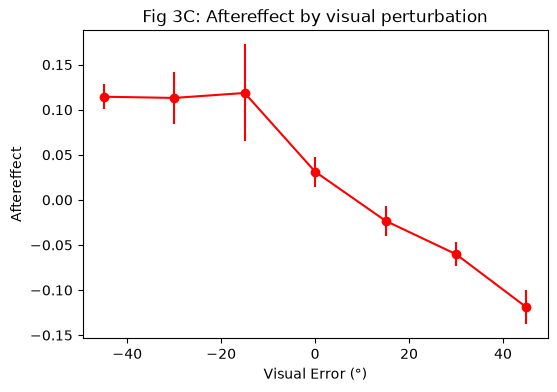

In [12]:
# Sort aftereffect by visual perturbation level
force_arrays_by_visual_perturbation = {}
for vis_pert, after_effect in zip(vis_vals, aftereffects):
    if vis_pert not in force_arrays_by_visual_perturbation:
        force_arrays_by_visual_perturbation[vis_pert] = []
    force_arrays_by_visual_perturbation[vis_pert].append(after_effect)

# Calculate means and standard errors for error bars
means = []
ses = []
for visual_pert in vis_pert_levels:
    forces_list = np.array(force_arrays_by_visual_perturbation[visual_pert])
    means.append(forces_list.mean())
    ses.append(forces_list.std() / np.sqrt(len(forces_list)))
    
#Plotting
# Reversing the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
means.reverse() # Flip the order to match up with the CW Hayashi visual perturbation levels
ses.reverse() 

plt.figure(figsize=(6, 4))
plt.errorbar(vis_pert_levels, means, yerr=ses, fmt='o-', color='red', capsize=0)
plt.xlabel('Visual Error (°)')
plt.ylabel('Aftereffect')
plt.title('Fig 3C: Aftereffect by visual perturbation')
plt.show()

**Figure 3D:**

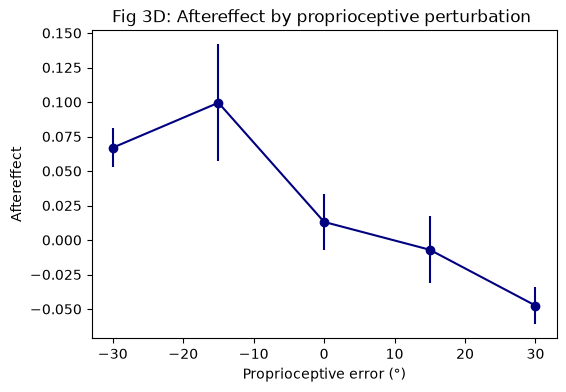

In [13]:
# Sort aftereffect by prop perturbation level
force_arrays_by_prop_perturbation = {}
for prop_pert, ae in zip(prop_vals, aftereffects):
    if prop_pert not in force_arrays_by_prop_perturbation:
        force_arrays_by_prop_perturbation[prop_pert] = []
    force_arrays_by_prop_perturbation[prop_pert].append(ae)

# Calculate means and standard errors for error bars
means = []
ses = []
for prop_pert in prop_pert_unmapped_levels:
    forces_list = np.array(force_arrays_by_prop_perturbation[prop_pert])
    means.append(forces_list.mean())
    ses.append(forces_list.std() / np.sqrt(len(forces_list)))
    
# Plotting
# Reversing the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
means.reverse() # Flip the order to match up with the CW Hayashi visual perturbation levels
ses.reverse()

plt.figure(figsize=(6, 4))
plt.errorbar(prop_pert_levels, means, yerr=ses, fmt='o-', color='navy', capsize=0)
plt.xlabel('Proprioceptive error (°)')
plt.ylabel('Aftereffect')
plt.title('Fig 3D: Aftereffect by proprioceptive perturbation ')
plt.show()

**Figure 4A-E:**

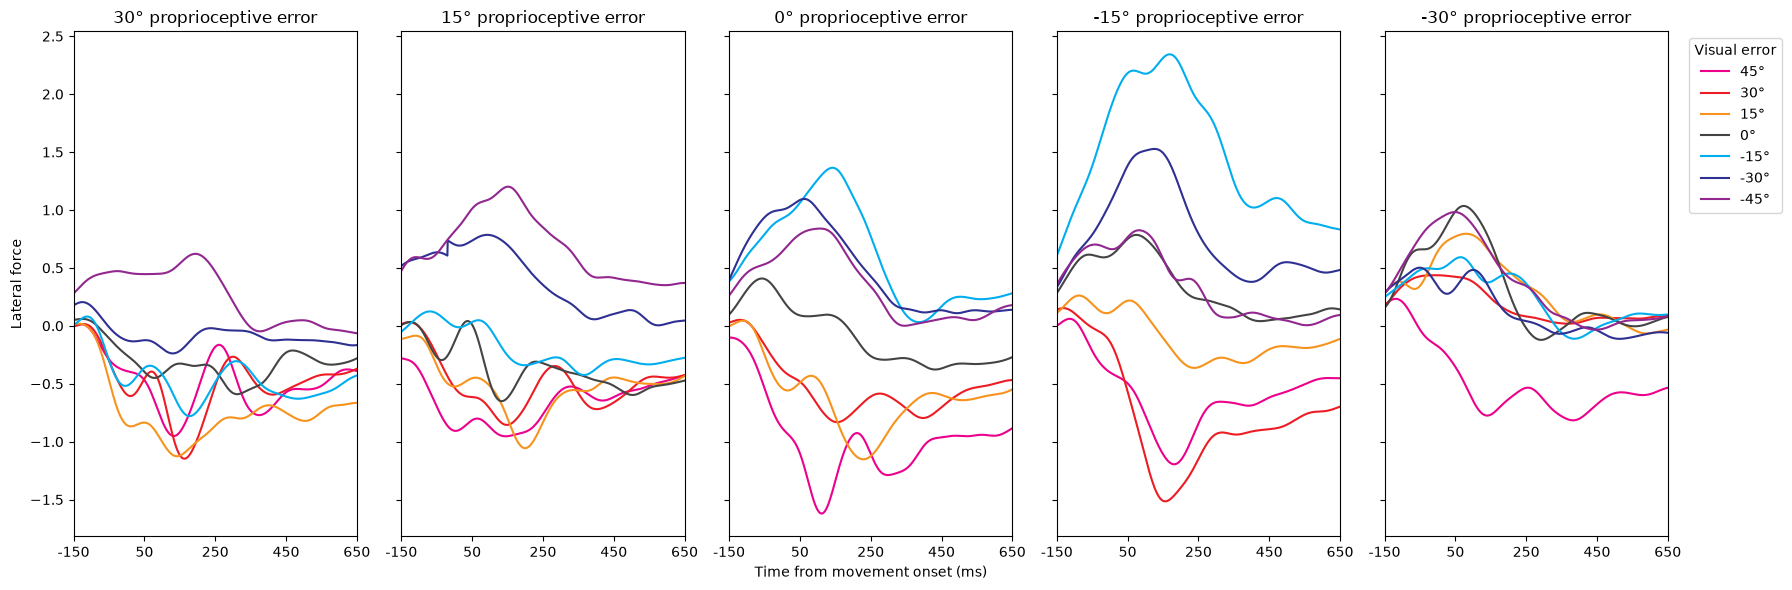

In [14]:
# combine aligned forces, and both kinds of perturbations into one list of tuples
total_trial_data = list(zip(aligned_forces, vis_vals, prop_vals))

#setup figure 4 a-e: avg force profile for each prop pert level (a-e), with lines for each vis pert level 
#sharey=True: all subolits have the same y-axis scales, ticks, limits, etc
fig, axes = plt.subplots(1, len(prop_pert_unmapped_levels), figsize=(18, 6), sharey=True)

# Iterate through each suplot (and corresponding proprioceptive perturbation level) 
for ax, prop in zip(axes, prop_pert_unmapped_levels):
    # Filter trials for the current proprioceptive perturbation level
    subset = [(force, vis_pert) for force, vis_pert, prop_pert in total_trial_data if prop_pert == prop]

    # group force profiles by visual perturbation level within prop pert lvl
    grouped = defaultdict(list)
    for force, vis_pert in subset:
        grouped[vis_pert].append(force)

    # Calculate average force profiles per visual perturbation level
    avg_forces = {}
    for vis_pert, force_list in grouped.items():
        max_len = max(len(force_array) for force_array in force_list)
        # Same logic as before - pad with nans to handle reaches / force profiles of different lengths
        padded = [
            np.pad(force_array, (0, max_len - len(force_array)), constant_values=np.nan)
            for force_array in force_list
        ]
        avg_forces[vis_pert] = np.nanmean(padded, axis=0)

   # Plot
    for vis_pert in vis_pert_levels:
        if vis_pert in avg_forces:
            avg = avg_forces[vis_pert]
            # Flipping the sign of the graphed visual perturbation to match Hayashi
            label = mapping_vis.get(vis_pert, str(vis_pert))
            color = color_map.get(label, None)
            ax.plot(avg, label=f'{label}°', color=color)

    # Set title of each subplot and x-axis formatting
    label = mapping.get(prop, str(prop))
    ax.set_title(f'{label}° proprioceptive error')
    
    # Allows us to format the x-axis in terms of time relative to RT/ force onset - not starting with 0
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: int(x - BUFFER)))
    ax.set_xlim(0, 800)

# Set axis labels and format legend location
axes[0].set_ylabel('Lateral force')
axes[2].set_xlabel('Time from movement onset (ms)')
axes[-1].legend(title='Visual error', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Figure 4F:**

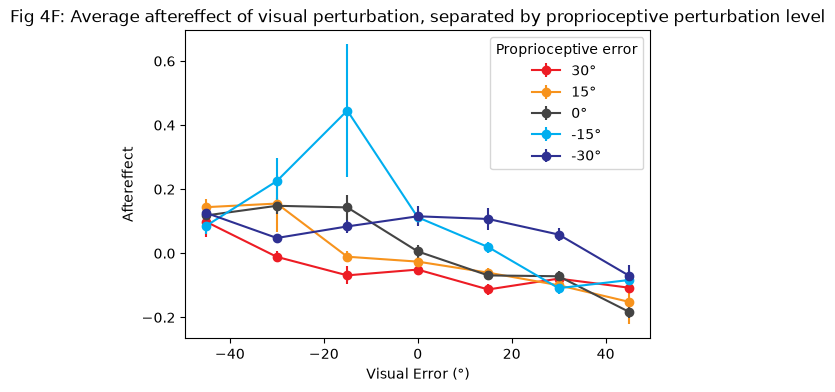

In [15]:
# Group after effect by proprioceptive level, then by visual perturbation
grouped = defaultdict(lambda: defaultdict(list))
for vis_pert, prop_pert, after in zip(vis_vals, prop_vals, aftereffects):
    grouped[prop_pert][vis_pert].append(after)

plt.figure(figsize=(6, 4))

for prop_pert in prop_pert_unmapped_levels:
    means = []
    ses = []
    
    # For each visual perturbation level, calc the mean and standard error of the after effect 
    for vis_pert in vis_pert_levels:
        data = np.array(grouped[prop_pert][vis_pert])
        means.append(data.mean())
        ses.append(data.std() / np.sqrt(len(data)))
    
    # Plot
    # Reversing the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
    means.reverse() # Flip the order to match up with the CW Hayashi visual perturbation level
    ses.reverse()
    
    label = mapping.get(prop_pert, str(prop_pert))
    color = color_map.get(label, None)
    plt.errorbar(vis_pert_levels, means, yerr=ses, fmt='o-', color= color, capsize=0, label=f'{label}°')

plt.xlabel('Visual Error (°)')
plt.ylabel('Aftereffect')
plt.title('Fig 4F: Average aftereffect of visual perturbation, separated by proprioceptive perturbation level')
plt.legend(title='Proprioceptive error')
plt.show()

**Figure 4G:**

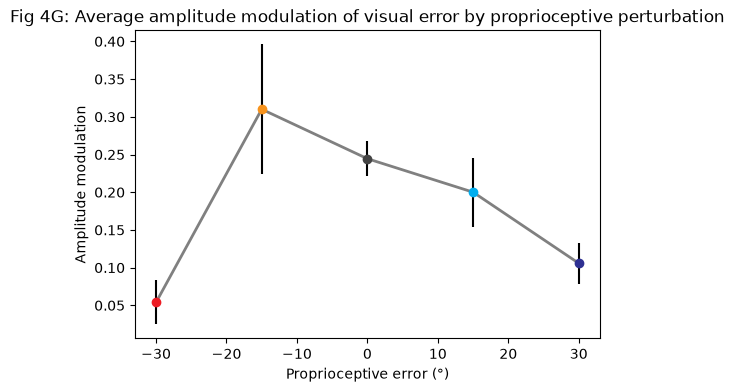

In [16]:
# Group after effect by proprioceptive level, then by visual perturbatopm
grouped = defaultdict(lambda: defaultdict(list))
for vis_pert, prop_pert, after in zip(vis_vals, prop_vals, aftereffects):
    grouped[prop_pert][vis_pert].append(after)

amp_means = []
amp_ses = []
for prop_pert in prop_pert_unmapped_levels:
    # Initialize empty arrays to hold aftereffects for pos and neg visual perturbations respectively
    pos_viserror_ae = []
    neg_viserror_ae = []
    
    
    for vis_pert in vis_pert_levels:
        # Extract aftereffects for the current proprioceptive and visual perturbation level
        data = np.array(grouped[prop_pert][vis_pert])
        
        if vis_pert > 0:
            pos_viserror_ae.extend(data)
        elif vis_pert < 0:
            neg_viserror_ae.extend(data)

    # Convert to numpy arrays for easier calculations 
    pos_viserror_ae = np.array(pos_viserror_ae)
    neg_viserror_ae = np.array(neg_viserror_ae)

    # Compute means for positive and negative visual perturbations
    pos_mean = pos_viserror_ae.mean()
    neg_mean = neg_viserror_ae.mean()

    # Compute amplitude modulation as the difference between the mean aftereffect for positive vs negative visual perturbations
    amp = pos_mean - neg_mean
    amp_means.append(amp)

    # Compute standard error of differences (a bit unconfident this is how you do it**)
    pos_se = pos_viserror_ae.std(ddof=1) / np.sqrt(len(pos_viserror_ae))
    neg_se = neg_viserror_ae.std(ddof=1) / np.sqrt(len(neg_viserror_ae))
    amp_se = np.sqrt(pos_se**2 + neg_se**2)
    amp_ses.append(amp_se)

# Plot
plt.figure(figsize=(6, 4))
# Flipping the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
amp_means.reverse() # Flip the order to match up with the CW Hayashi visual perturbation levels
amp_ses.reverse()

for i, prop_pert in enumerate(prop_pert_levels):
    # Here we take the negative propropceptive perturbation because we are iterating through a list of the un-flipped perturbations 
    # When we take from the mapping variable, they are already flipped so we don't need to flip it manually 
    color = color_map.get(-1*prop_pert, None)
    plt.errorbar(prop_pert_levels[i], amp_means[i], yerr=amp_ses[i],
                 fmt='o-', color=color, ecolor='black', capsize=0)
plt.plot(prop_pert_levels, amp_means, color='gray', linewidth=2, zorder=0)

plt.xlabel('Proprioceptive error (°)')
plt.ylabel('Amplitude modulation')
plt.title('Fig 4G: Average amplitude modulation of visual error by proprioceptive perturbation')
plt.show()

**Figure 4H:**

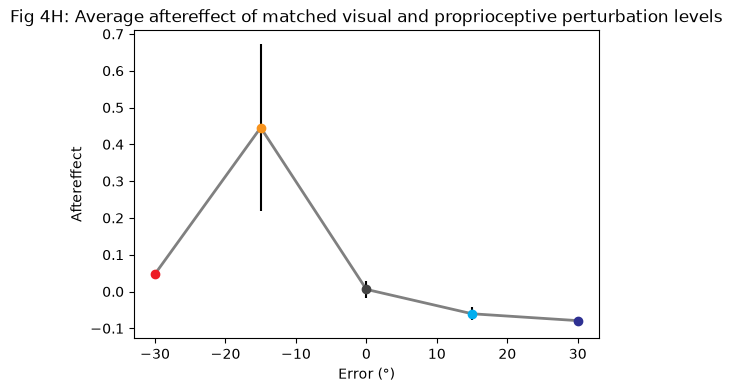

In [17]:
# Convert the proprioceptive perturbation values to degrees using the mapping
# Using prop_vals directly so they stay in the same trial order as the aftereffects and visual perturbations 
# As a result, we want to multiply by -1 because we don't want to use the flipped perts yet -- instead, we want to 
# perform all calculations and match the vis and prop pert levels first, then flip them before graphing
prop_vals_deg = np.array([-1*mapping[p] for p in prop_vals])
matched = {}

# Sort and only extract the after effects on trials where visual and prop perts are equivalent 
for vis, prop_deg, ae in zip(vis_vals, prop_vals_deg, aftereffects):
    if vis == prop_deg:
        if vis not in matched:
            matched[vis] = []
        matched[vis].append(ae)

matched_levels = sorted(matched.keys())

means = []
ses = []

# For each matching perturbation level, calculate the mean and standard error of the after effect 
for level in matched_levels:
    data = np.array(matched[level])
    means.append(data.mean())
    ses.append(data.std(ddof=1) / np.sqrt(len(data)))

# Plotting
plt.figure(figsize=(6, 4))
# Flipping the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
means.reverse() # Flip the order to match up with the CW Hayashi visual perturbation levels
ses.reverse()
for i, pert in enumerate(matched_levels):
    # Here we take the negative propropceptive perturbation because we are iterating through a list of the un-flipped perturbations 
    # When we take from the mapping variable, they are already flipped so we don't need to flip it manually
    color = color_map.get(-1*pert, None)
    plt.errorbar(pert, means[i], yerr=ses[i],
                 fmt='o-', color=color, ecolor='black', capsize=0)
    
plt.plot(matched_levels, means, color='gray', linewidth=2, zorder=0)

plt.xlabel('Error (°)')
plt.ylabel('Aftereffect')
plt.title('Fig 4H: Average aftereffect of matched visual and proprioceptive perturbation levels')
plt.show()

# Yoyo's data looks very different to the Hayashi paper, not sure why.    

----

In [18]:
# NOT A FIGURE FROM HAYASHI! 
# Just meant to be a quick visualization of all the force profiles in the data set, split by visual perturbation level. 
# This is to check that the data looks reasonable and that the alignment worked as expected.

# ALSO IMPORTANT - this figure does not show the flipped perturbation levels, but rather the ones we used in our experiment (opposite direction as Hayashi)

plt.figure(figsize=(10, 6))

for force_array, vis_pert in  forces_vis:
    color = color_map.get(vis_pert, None)
    plt.plot(force_array, color=color, alpha=0.5, linewidth=1)

legend_elements = [
    Line2D([0], [0], color=color_map.get(p, None), lw=2, label=str(p))
    for p in vis_pert_levels
]

ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: int(x - BUFFER)))
ax.set_xlim(left=0, right=1000)

plt.xlabel('Time')
plt.ylabel('Force X')
plt.title('Aligned Force X by Visual Perturbation')
plt.legend(handles=legend_elements, title="Visual Perturbation")

# If you want to see the figure, comment plt.close() and uncomment plt.show()
plt.close()
#plt.show()

In [19]:
# Also not a figure from Hayashi -- same visualization as above but for the proprioceptive perturbation levels instead of the visual perturbation levels
plt.figure(figsize=(10, 6))

for force_array, prop_pert in forces_prop:
    color = color_map.get(prop_pert, None)
    plt.plot(force_array, color=color, alpha=0.5, linewidth=1)

legend_elements = [
    Line2D([0], [0], color=color_map.get(p, None), lw=2, label=str(mapping.get(p, p)))
    for p in prop_pert_levels
]

plt.legend(handles=legend_elements, title="Proprioceptive Perturbation")

ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: int(x - BUFFER)))
ax.set_xlim(left=0, right=1000)

plt.xlabel('Time')
plt.ylabel('Force X')
plt.title('Aligned Force X by Proprioceptive Perturbation')

plt.close()
#plt.show()